## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [49]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('./data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

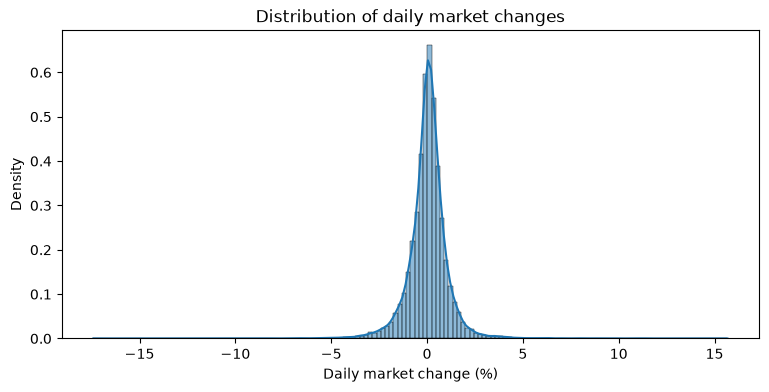

In [50]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

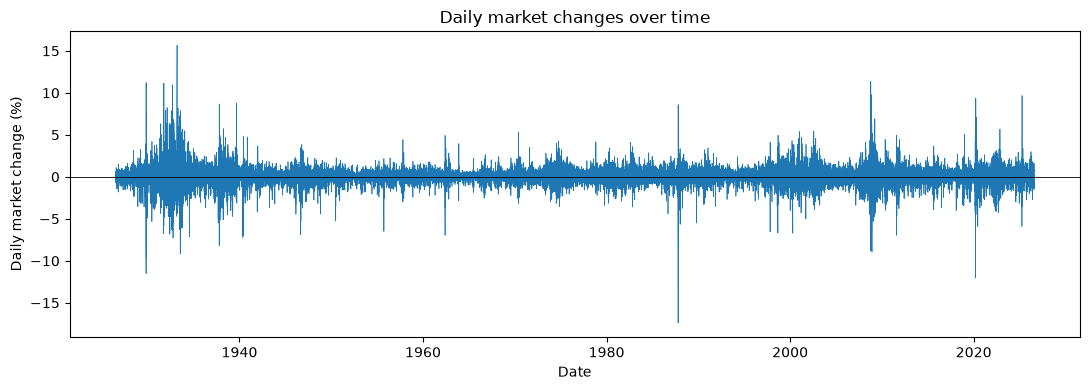

In [51]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [52]:
df_market = df.copy()

df_market['current_return'] = df_market['market_return_pct']
df_market['next_return'] = df_market['market_return_pct'].shift(-1)

df_market['current_category'] = np.where(df_market['current_return'] > 0, 'Up', 'Down')
df_market['next_category'] = np.where(df_market['next_return'] > 0, 'Up', 'Down')

df_market = df_market.dropna(subset=['next_return']).copy()

df_market[['date', 'current_return', 'next_return',
           'current_category', 'next_category']].head()


,date,current_return,next_return,current_category,next_category
0,1926-07-01,0.10,0.46,Up,Up
1,1926-07-02,0.46,0.18,Up,Up
2,1926-07-06,0.18,0.10,Up,Up
3,1926-07-07,0.10,0.23,Up,Up
4,1926-07-08,0.23,-0.70,Up,Down


In [53]:
joint_pmf = pd.crosstab(
    df_market['current_category'],
    df_market['next_category'],
    normalize=True,
    margins=True
)

joint_pmf

next_category,Down,Up,All
current_category,,,
Down,0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


In [54]:
conditional_pmf = pd.crosstab(
    df_market['current_category'],
    df_market['next_category'],
    normalize='index'
)

conditional_pmf

next_category,Down,Up
current_category,,
Down,0.496221,0.503779
Up,0.416974,0.583026


**Are up transitions more or less common than down transitions?**

Up transitions are more common than Down transitions.

**Are you more likely to transition to an Up day from a Down or Up day?**

More likely to transition to an Up day from another Up day.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

1. `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?

In [55]:
df_market_5 = df.copy()

bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf]
labels = ['Large loss', 'Small loss', 'Near zero',
          'Small gain', 'Large gain']

df_market_5['current_category'] = pd.cut(
    df_market_5['market_return_pct'],
    bins=bins,
    labels=labels
)

df_market_5['current_category'].value_counts(sort=False)

current_category
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859
Name: count, dtype: int64

The most common are small gain and the least are large loss.

2. Compute the joint PMF and marginals. Which transitions are most likely to occur? 

In [56]:
df_market_5['next_category'] = df_market_5['current_category'].shift(-1)

df_market_5 = df_market_5.dropna(subset=['next_category']).copy()

joint_pmf = pd.crosstab(
    df_market_5['current_category'],
    df_market_5['next_category'],
    normalize=True,
    margins=True
)

joint_pmf

next_category,Large loss,Small loss,Near zero,Small gain,Large gain,All
current_category,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


In [57]:
transition_probabilities = joint_pmf.drop(
    index='All', columns='All'
)

most_likely = transition_probabilities.stack().idxmax()
highest_probability = transition_probabilities.stack().max()

print(f"Most likely transition: {most_likely[0]} -> {most_likely[1]}")
print(f"Probability: {highest_probability:.2%}")


Most likely transition: Small gain -> Small gain
Probability: 15.94%


The most likely transition is from a Small gain to another Small gain.

3. Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?

In [58]:
conditional_pmf = pd.crosstab(
    df_market_5['current_category'],
    df_market_5['next_category'],
    normalize='index'
)

conditional_pmf

next_category,Large loss,Small loss,Near zero,Small gain,Large gain
current_category,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


In [59]:
for current_state, probabilities in conditional_pmf.iterrows():
    top_two = probabilities.nlargest(2)

    print(f"\nCurrent state: {current_state}")
    for next_state, probability in top_two.items():
        print(f"  {next_state}: {probability:.2%}")



Current state: Large loss
  Small gain: 26.50%
  Small loss: 25.92%

Current state: Small loss
  Small gain: 34.50%
  Small loss: 31.28%

Current state: Near zero
  Small gain: 37.69%
  Small loss: 32.08%

Current state: Small gain
  Small gain: 42.85%
  Small loss: 26.89%

Current state: Large gain
  Small gain: 34.77%
  Small loss: 23.47%


Small gain and Small loss are the two most likely future states. The probabilities are not very close to a uniform distribution of .20. Predicting the next state is difficult because no single category has a probability greater than 0.50.

4. For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [60]:
df_market_5['next_return'] = df['market_return_pct'].shift(-1)

return_summary = (
    df_market_5
    .groupby('current_category', observed=True)['next_return']
    .describe()
)

return_summary


,count,mean,std,min,25%,50%,75%,max
current_category,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


In [61]:
highest_volatility = return_summary['std'].idxmax()

print(f"Highest next day volatility: {highest_volatility}")


Highest next day volatility: Large loss


The expected returns for tomorrow are -0.0383% after a Large loss, -0.0438% after a Small loss, 0.0150% after Near zero, 0.1068% after a Small gain, and 0.1631% after a Large gain.

The min and max returns vary across states, with the largest differences occurring after a Large loss or Large gain. The other states also vary, but within smaller ranges.

The states with the highest standard deviation for tomorrow's percent returns are Large loss and Large gain.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

1. Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 

In [62]:
df_market_21 = df.copy()

df_market_21['y_t'] = pd.qcut(
    df_market_21['market_return_pct'],
    q=21,
    labels=False
)

df_market_21['y_tp1'] = df_market_21['y_t'].shift(-1)
df_market_21 = df_market_21.dropna(subset=['y_tp1']).copy()

df_market_21[['market_return_pct', 'y_t', 'y_tp1']].head(21)

,market_return_pct,y_t,y_tp1
0,0.10,10,15.0
1,0.46,15,11.0
2,0.18,11,10.0
3,0.10,10,12.0
4,0.23,12,3.0
5,-0.70,3,16.0
6,0.62,16,10.0
7,0.05,10,15.0
8,0.49,15,10.0
9,0.05,10,4.0


2. Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

joint_pmf = pd.crosstab(
    df_market_21['y_t'],
    df_market_21['y_tp1'],
    normalize=True
)

joint_adjusted = joint_pmf - 1 / 21**2

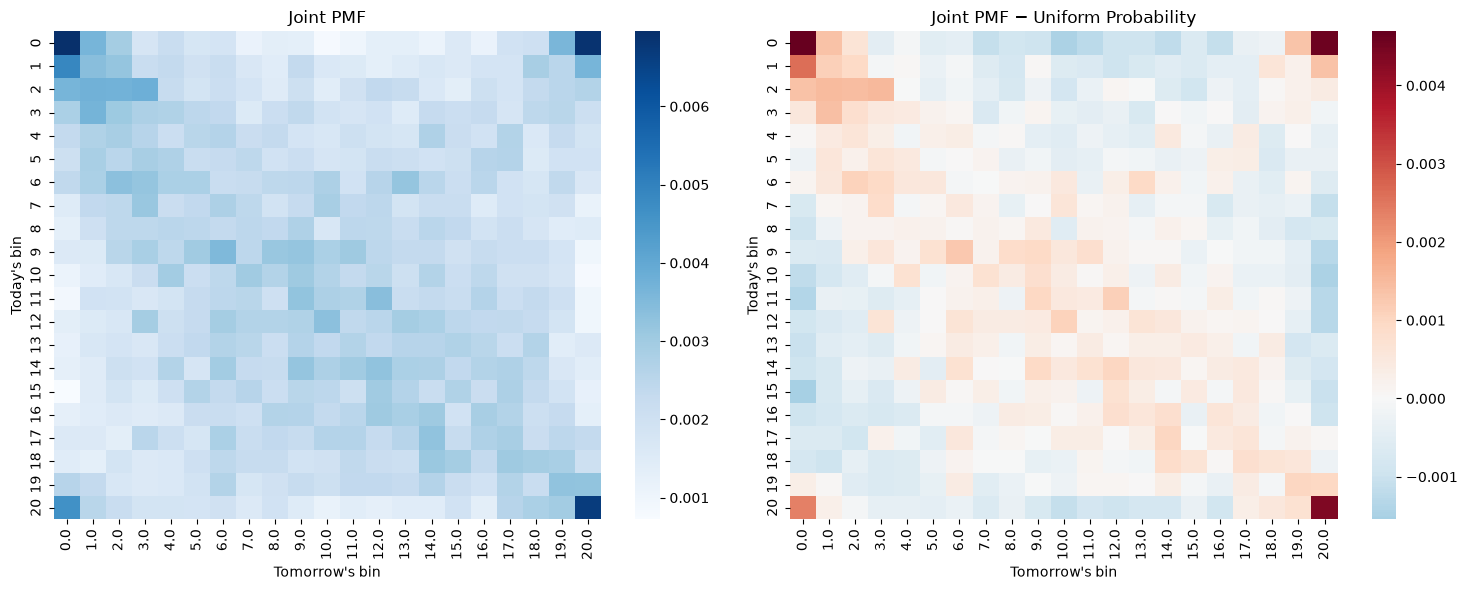

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(joint_pmf, cmap='Blues', ax=axes[0])
axes[0].set_title('Joint PMF')
axes[0].set_xlabel("Tomorrow's bin")
axes[0].set_ylabel("Today's bin")

sns.heatmap(joint_adjusted, cmap='RdBu_r', center=0, ax=axes[1])
axes[1].set_title('Joint PMF − Uniform Probability')
axes[1].set_xlabel("Tomorrow's bin")
axes[1].set_ylabel("Today's bin")

plt.tight_layout()
plt.show()

From the heatmaps, we can notice that extreme returns tend to be followed by other extreme returns. This means large market movements tend to be followed by other large movements, whether positive or negative.

3. Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.

In [65]:
conditional_pmf = pd.crosstab(
    df_market_21['y_t'],
    df_market_21['y_tp1'],
    normalize='index'
)

conditional_adjusted = conditional_pmf - 1 / 21

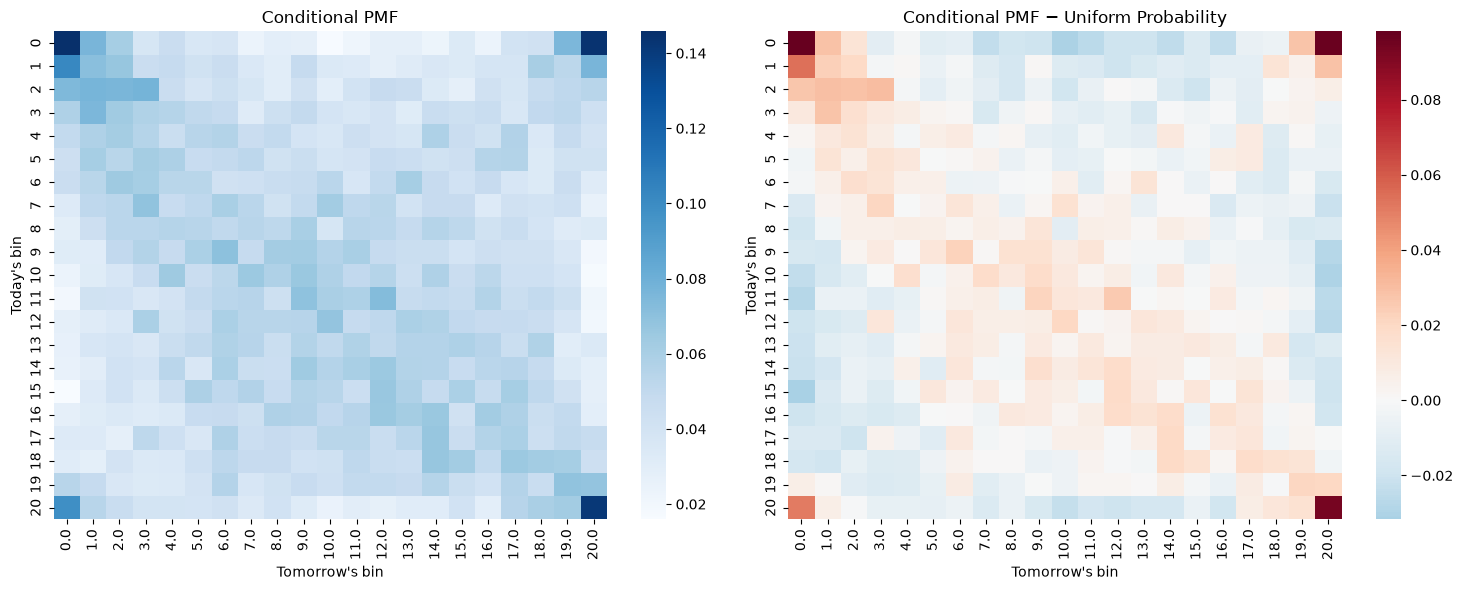

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(conditional_pmf, cmap='Blues', ax=axes[0])
axes[0].set_title('Conditional PMF')
axes[0].set_xlabel("Tomorrow's bin")
axes[0].set_ylabel("Today's bin")

sns.heatmap(conditional_adjusted, cmap='RdBu_r', center=0, ax=axes[1])
axes[1].set_title('Conditional PMF − Uniform Probability')
axes[1].set_xlabel("Tomorrow's bin")
axes[1].set_ylabel("Today's bin")

plt.tight_layout()
plt.show()

We see the same pattern where large market movements tend to be followed by other large movements. Other than that, there is no clear pattern, making it difficult to predict tomorrow's return.

4. For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 

In [69]:
df_market_21['next_return'] = df['market_return_pct'].shift(-1)

return_summary = (
    df_market_21.groupby('y_t')['next_return']
    .agg(['min', 'mean', 'max'])
)

return_summary

,min,mean,max
y_t,,,
0,-17.41,-0.013713,11.22
1,-7.36,-0.076712,6.36
2,-8.79,-0.097084,11.36
3,-8.28,-0.058594,6.16
4,-6.89,-0.024211,4.56
5,-11.23,-0.022692,6.37
6,-3.94,-0.030241,7.37
7,-3.40,-0.014303,4.76
8,-6.00,0.025860,5.49


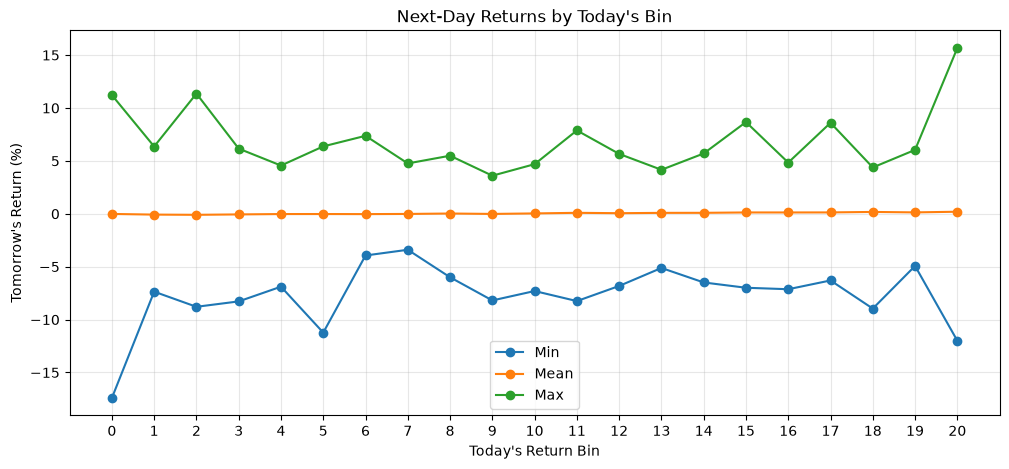

In [70]:
plt.figure(figsize=(12, 5))

for column in ['min', 'mean', 'max']:
    plt.plot(
        return_summary.index,
        return_summary[column],
        marker='o',
        label=column.capitalize()
    )

plt.xlabel("Today's Return Bin")
plt.ylabel("Tomorrow's Return (%)")
plt.title("Next-Day Returns by Today's Bin")
plt.xticks(range(21))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

On average, tomorrow's returns stay close to zero. We can also see that large market movements tend to be followed by a wider range of returns, while smaller movements generally have a narrower range.

5. For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 

In [71]:
return_std = (
    df_market_21.groupby('y_t')['next_return']
    .std()
)

return_std

y_t
0     2.140465
1     1.285882
2     1.227976
3     1.049607
4     0.989470
5     1.024761
6     0.930389
7     0.835663
8     0.853220
9     0.811559
10    0.805212
11    0.791857
12    0.784100
13    0.816509
14    0.831233
15    0.789961
16    0.826667
17    0.959673
18    0.900844
19    1.099897
20    1.702623
Name: next_return, dtype: float64

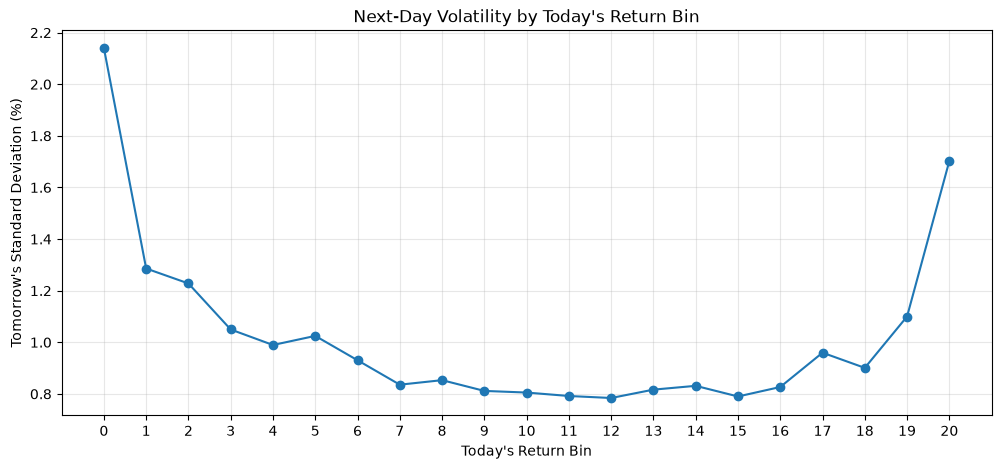

In [72]:
plt.figure(figsize=(12, 5))

plt.plot(
    return_std.index,
    return_std.values,
    marker='o'
)

plt.xlabel("Today's Return Bin")
plt.ylabel("Tomorrow's Standard Deviation (%)")
plt.title("Next-Day Volatility by Today's Return Bin")
plt.xticks(range(21))
plt.grid(alpha=0.3)
plt.show()

Extreme market returns tend to be followed by higher volatility, meaning tomorrow's returns fluctuate more and smaller market movements have lower volatility.

5. How easy is it to predict the market?

From our analysis, we can see that large losses or gains tend to be followed by a wider range of possible returns, while smaller movements tend to be followed by a narrower range. We don't see a clear pattern indicating whether tomorrow's return will be positive or negative. This makes predicting the market difficult. We can get an idea of how much tomorrow's returns might vary, but we still have uncertainty about their direction.